In [ ]:
%load_ext autoreload
%autoreload 2

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Image, display

from data_analysis.config import load_config

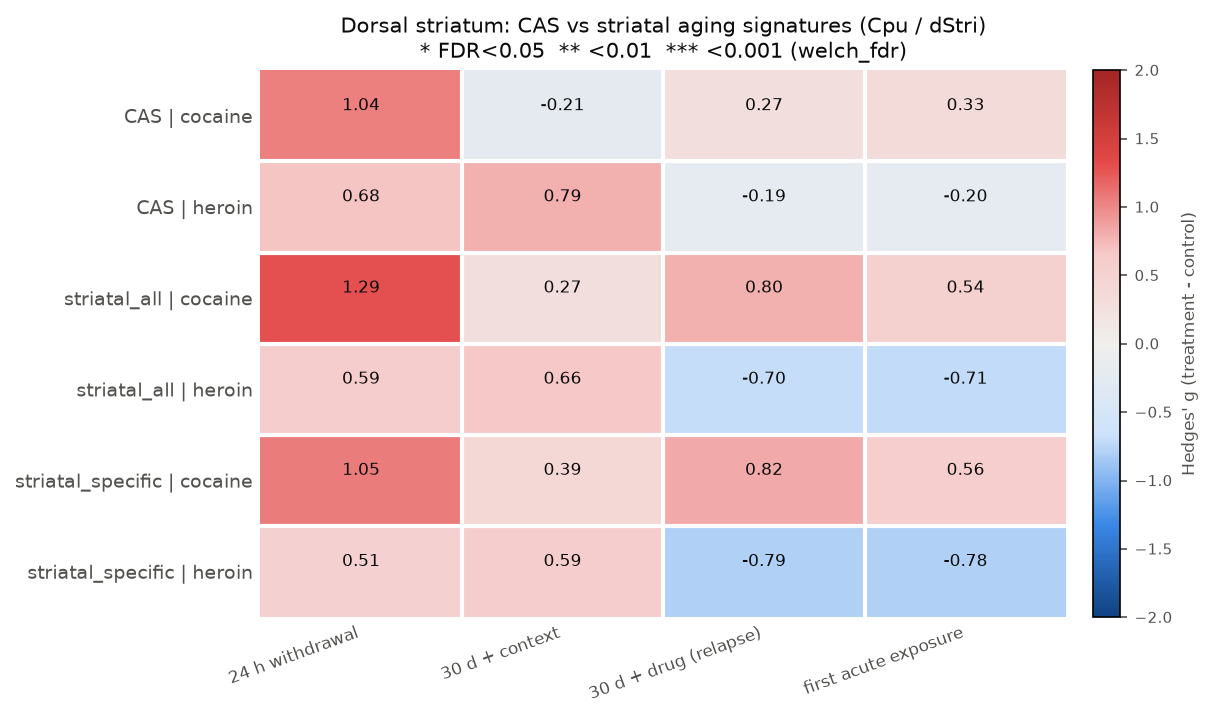

In [2]:
cfg = load_config()
tables, figs = cfg["paths"]["tables"], cfg["paths"]["figures"]
res = pd.read_csv(tables / "table_striatal_signature_stats.csv")
genes = pd.read_csv(tables / "table_striatal_signature_genes.csv")
display(Image(figs / "fig_striatal_signature_heatmap.png"))

In [3]:
res.pivot_table(index=["signature", "drug"], columns="design", values="g").round(2)

design                     24 h withdrawal  30 d + context  \
signature         drug                                       
CAS               cocaine             1.04           -0.21   
                  heroin              0.68            0.79   
striatal_all      cocaine             1.29            0.27   
                  heroin              0.59            0.66   
striatal_specific cocaine             1.05            0.39   
                  heroin              0.51            0.59   

design                     30 d + drug (relapse)  first acute exposure  
signature         drug                                                  
CAS               cocaine                   0.27                  0.33  
                  heroin                   -0.19                 -0.20  
striatal_all      cocaine                   0.80                  0.54  
                  heroin                   -0.70                 -0.71  
striatal_specific cocaine                   0.82                  0.56  
                  heroin                   -0.79                 -0.78

,signature,n_genes,n_in_hahn_counts,sign_agreement,rho_correlation,frac_p_lt_0.05_ours
0,striatal_all,498,498,1.0,0.996159,0.995984
1,striatal_specific,423,423,1.0,0.995626,0.995272


Text(0.5, 1.0, 'Caudate putamen age correlation: published vs recomputed')

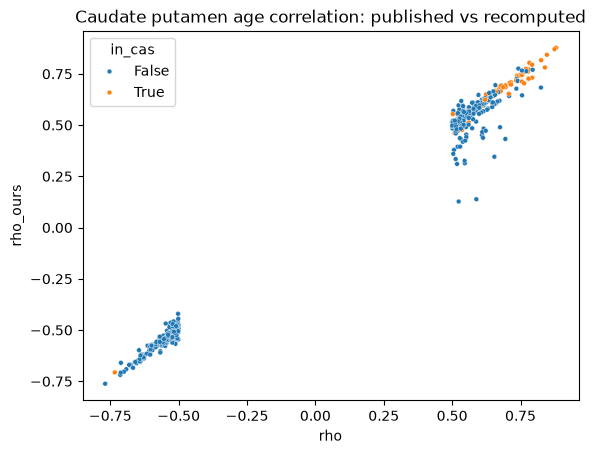

In [4]:
display(pd.read_csv(tables / "table_striatal_crossval.csv"))
sns.scatterplot(data=genes, x="rho", y="rho_ours", hue="in_cas", s=12)
plt.title("Caudate putamen age correlation: published vs recomputed")

In [5]:
genes.groupby(["in_cas", "direction"]).size()

in_cas  direction
False   down         179
        up           244
True    down           5
        up            70
dtype: int64

In [6]:
res.drop_duplicates("signature")[["signature", "hahn_cp_slope", "hahn_cp_slope_p"]]

,signature,hahn_cp_slope,hahn_cp_slope_p
0,CAS,0.185647,8.538206e-20
8,striatal_all,0.253133,8.140471e-25
16,striatal_specific,0.195705,6.663044e-26


In [7]:
genes[genes["gene"].str.match(r"^(March|Sept|Dec)\d+$")][["gene", "direction", "rho", "ensembl_gene_id"]]

,gene,direction,rho,ensembl_gene_id
433,March11,down,-0.547564,ENSMUSG00000022269
